In [1]:
import pandas as pd
import requests
import numpy as np

In [2]:
x = np.load('../../output/data_eagles_vezhen/qrf/vezhen_x3.npy', allow_pickle=True)

In [3]:
features = [
    'SPEED', 'COURSE', 'currentSpeed', 'gust', 'swellHeight',
    'waveHeight', 'windSpeed', 'dif', 'COURSE-dif', 'delta_dif',
    'COURSE_vec_x', 'COURSE_vec_y', 'currentDirection_vec_x',
    'currentDirection_vec_y', 'swellDirection_vec_x',
    'swellDirection_vec_y', 'waveDirection_vec_x', 'waveDirection_vec_y',
    'windDirection_vec_x', 'windDirection_vec_y'
]
df_x=pd.DataFrame(x.reshape((-1, 5, 20))[:, 0, :], columns=features)

In [4]:
import pickle
with open('../../output/data_eagles_vezhen/min-max-scaler-eagles-vezhen.pkl', 'rb+') as f:
    scaler = pickle.load(f)

/home/lukas/straipsnis/qrf-venv/lib/python3.12/site-packages/sklearn/base.py:442: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.9.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [ ]:
scaler.data_min_[5]

array([0.  , 0.  , 0.62, 0.02, 0.01, 0.5 ])

In [8]:
min_max_scale_cols = [
    'SPEED',
    'currentSpeed',
    'gust',
    'swellHeight',
    'waveHeight',
    'windSpeed',
]
vezhen_true = scaler.inverse_transform(df_x[min_max_scale_cols])

In [9]:
import matplotlib.pyplot as plt

In [12]:
vezhen_true.shape

(346, 6)

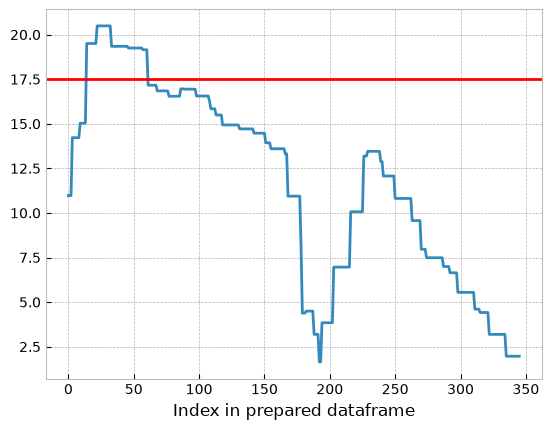

In [17]:
plt.style.use('bmh')
plt.rcParams['axes.facecolor'] = 'white'
wind_index=5 #look-up file data_preparation_eagles.py
plt.plot( vezhen_true[:, 5] )
plt.xlabel('Index in prepared dataframe')
plt.ylabel('')
plt.axhline(y=17.5, color='red')

In [20]:
np.array(range(0, vezhen_true.shape[0]))[ vezhen_true[:, 5] > 17.5 ]

array([14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30,
       31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47,
       48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60])

<Axes: >

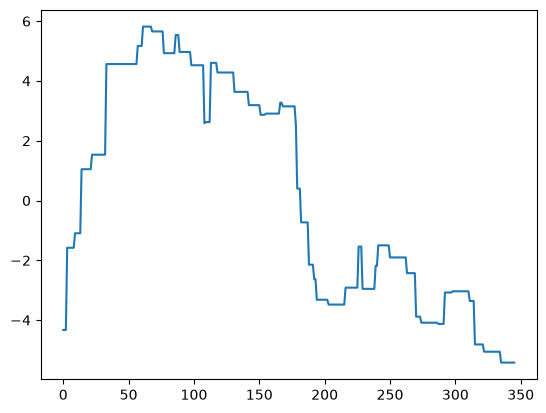

In [36]:
waveh_index=4 #look-up file data_preparation_eagles.py
waveh_min = scaler.data_min_[waveh_index]
waveh_range = scaler.data_range_[waveh_index]
((df_x['waveHeight'] + waveh_min) * waveh_range).plot()

<Axes: >

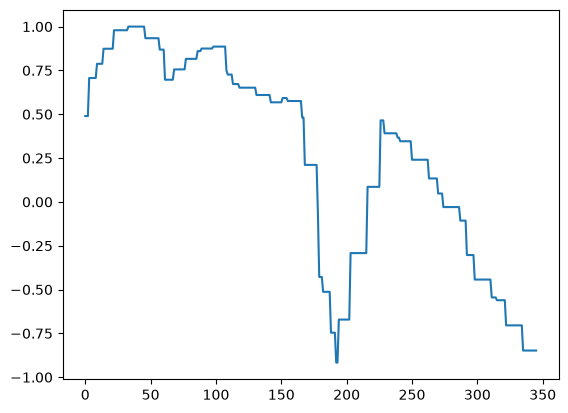

In [25]:
df_x['gust'].plot()

In [2]:
vezhen_df = pd.read_csv('../../data/VEZHEN_PositionReport_5min_25Jan2025_26Jan2025.csv')

In [4]:
vezhen_df[['LATITUDE', 'LONGITUDE']]

,LATITUDE,LONGITUDE
0,59.79072,24.36978
1,59.78778,24.34069
2,59.78457,24.31065
3,59.78089,24.28208
4,59.77715,24.25339
...,...,...
539,56.05912,15.52331
540,56.05917,15.52342
541,56.05923,15.52365
542,56.05931,15.52388


<Axes: >

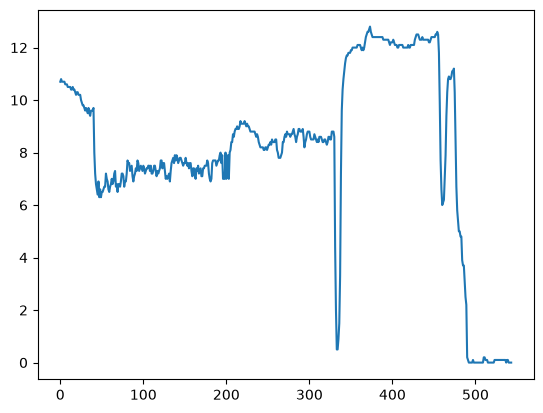

In [5]:
vezhen_df['SPEED'].plot()

In [19]:
import sys
sys.path.append('../../')
from src.eagles_vezhen.meteorological_data_collection import get_stormglass_req

In [29]:
for ix, series in vezhen_df.iterrows():

    if ix >= 2:
        continue

    print(ix)
    lon = series['LONGITUDE']
    lat = series['LATITUDE']

    series_datetime = pd.to_datetime(series['DATE TIME (UTC)'])
    print( series_datetime.to_pydatetime().normalize() )

0


AttributeError: 'datetime.datetime' object has no attribute 'normalize'

In [ ]:
get_stormglass_req()